# SINACON — trích dữ liệu một lần

**Để làm gì:** log thô rất nặng (mỗi tủ vài trăm MB). Notebook này đọc log **một lần**, giữ lại đúng phần các bước sau cần, cất ra file nhỏ (khoảng 5 MB mỗi tủ). Sau đó tính cửa sổ thời gian, chạy mô hình… chỉ đọc file nhỏ này, mất vài giây.

**Giữ lại gì (mỗi tủ một file):**
- mỗi lần trạng thái / mã lỗi của APU và cả tủ thay đổi (APU Stat Trig, APS Stat Trig);
- warning của tủ;
- nhiệt độ mỗi phút của 4 APU (APU Stat 60s).

**Đọc từ:** `Trung Nam/01_log/<đợt>` (chỉ đọc). **Ghi vào:** `MyDrive/SINACON_mo_hinh_lai/bang_trung_gian/<đợt>/`.

**Cách chạy:** ô 1 → ô 2 → ô 3. Ô 2 lâu (khoảng 40 giây mỗi tủ, cả đợt khoảng 1 giờ). Drive ngắt giữa chừng thì chạy lại ô 1 và ô 2: tủ nào xong rồi sẽ bỏ qua, làm tiếp chỗ dở.

In [1]:
#@title 1. Kết nối Drive và lấy code
import subprocess, sys
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')
# Code nằm ở nhánh fault-diagnosis (repo công khai, không cần token)
REPO_URL = 'https://github.com/phanthutrang410/OPTIMA-Core.git'
BRANCH = 'fault-diagnosis'
CODE_DIR = Path('/content/OPTIMA-Core')
cmds = ([['git', '-C', str(CODE_DIR), 'fetch', 'origin', BRANCH],
         ['git', '-C', str(CODE_DIR), 'checkout', '-B', BRANCH, 'origin/' + BRANCH]]
        if (CODE_DIR / '.git').is_dir() else [['git', 'clone', '--branch', BRANCH, REPO_URL, str(CODE_DIR)]])
for c in cmds:
    subprocess.run(c, check=True)
sys.path.insert(0, str(CODE_DIR / 'src'))
import importlib, sinacon.extract
importlib.reload(sinacon.extract)
print('Code version:', subprocess.check_output(['git', '-C', str(CODE_DIR), 'rev-parse', '--short', 'HEAD'], text=True).strip())

Mounted at /content/drive
Code version: 1d0ccd5


In [4]:
#@title 2. Trích dữ liệu một đợt (lâu: khoảng 40 giây mỗi tủ)
DOT = 'Tháng 4–6/2026 (04/04–03/06)'  #@param ['Tháng 4–6/2026 (04/04–03/06)', 'Tháng 1–3/2026 (12/01–12/03)', 'Tháng 6–8/2026 (13/06–13/08)', 'Tháng 8–10/2026 (13/08–31/10)', 'Tháng 10/2025']
CHI_TU = ''  #@param {type:'string'}
# Để trống = mọi tủ. Muốn thử vài tủ trước: gõ vd 1.1, 4.1
from sinacon import explore as ex, extract as tr
ROOT = ex.find_period('/content/drive', '', DOT)
OUT = Path('/content/drive/MyDrive/SINACON_mo_hinh_lai/bang_trung_gian') / ex.PERIODS[DOT][2]
print('Đọc từ:', ROOT)
print('Ghi vào:', OUT)
tu = [x.strip() for x in CHI_TU.split(',') if x.strip()] or None
bang = tr.extract_period(ROOT, OUT, tu)


Đọc từ: /content/drive/.shortcut-targets-by-id/1QH7JFsL_nG25lNxnxULxFvLCHxHsHl0g/Trung Nam/01_log/2026-04-04_2026-06-04
Ghi vào: /content/drive/MyDrive/SINACON_mo_hinh_lai/bang_trung_gian/thang_4_6
Tìm thấy 100 tủ trong /content/drive/.shortcut-targets-by-id/1QH7JFsL_nG25lNxnxULxFvLCHxHsHl0g/Trung Nam/01_log/2026-04-04_2026-06-04
[2/100] 1.2 APS-000311: 61 ngày, 65413 dòng trạng thái, 342956 dòng nhiệt (67 s)
[3/100] 1.3 APS-000327: 61 ngày, 74678 dòng trạng thái, 344168 dòng nhiệt (72 s)
[4/100] 1.4 APS-000451: 61 ngày, 66129 dòng trạng thái, 342852 dòng nhiệt (65 s)
[5/100] 2.1 APS-000336: 61 ngày, 64385 dòng trạng thái, 343092 dòng nhiệt (74 s)
[6/100] 2.2 APS-000400: 61 ngày, 54783 dòng trạng thái, 342988 dòng nhiệt (28 s)
[7/100] 2.3 APS-000372: 61 ngày, 56854 dòng trạng thái, 342700 dòng nhiệt (55 s)
[8/100] 2.4 APS-000357: 61 ngày, 71688 dòng trạng thái, 339690 dòng nhiệt (59 s)
[9/100] 3.1 APS-000333: 61 ngày, 70582 dòng trạng thái, 332674 dòng nhiệt (69 s)
[10/100] 3.2 APS-000

In [5]:
#@title 3. Đã trích được gì
bang = tr.summary(OUT)
print(f'{len(bang)} tủ đã trích trong {OUT}')
sai = bang[~bang['dung_ma_aps']]
if len(sai):
    print('!!! Thư mục xếp nhầm tủ (mã APS trong file khác với tủ):'); display(sai[['tu', 'aps']])
display(bang)


100 tủ đã trích trong /content/drive/MyDrive/SINACON_mo_hinh_lai/bang_trung_gian/thang_4_6
!!! Thư mục xếp nhầm tủ (mã APS trong file khác với tủ):


,tu,aps
97,9.2,APS-000322
98,9.3,APS-000354


,tu,aps,dung_ma_aps,dang,so_ngay,tu_ngay,den_ngay,dong_trang_thai,lan_warning,dong_nhiet
0,1.1,APS-000370,True,log ngày,61,2026-04-04 00:00:00.002,2026-06-03 09:05:03.536,66330,3557,342644
1,1.2,APS-000311,True,log ngày,61,2026-04-04 00:00:00.004,2026-06-03 09:11:03.974,65413,9171,342956
2,1.3,APS-000327,True,log ngày,61,2026-04-04 00:00:00.009,2026-06-03 13:37:57.391,74678,7261,344168
3,1.4,APS-000451,True,log ngày,61,2026-04-04 00:00:00.004,2026-06-03 09:26:42.372,66129,19422,342852
4,10.1,APS-000261,True,log ngày,41,2026-04-04 00:00:00.002,2026-05-14 17:58:21.906,45754,1854,229656
...,...,...,...,...,...,...,...,...,...,...
95,8.5,APS-000349,True,log ngày,60,2026-04-05 00:00:00.003,2026-06-03 09:42:58.164,67881,5314,331150
96,9.1,APS-000322,True,log ngày,59,2026-04-05 00:00:00.004,2026-06-02 18:10:22.992,79828,7209,332708
97,9.2,APS-000322,False,log ngày,61,2026-04-04 00:00:00.004,2026-06-03 10:26:00.592,81521,7343,341024
98,9.3,APS-000354,False,log ngày,61,2026-04-04 00:00:00.000,2026-06-03 10:40:32.188,76184,7582,342052


## Bước kế tiếp — tính cửa sổ thời gian từ các file nhỏ

Chạy **sau khi ô 2 đã trích xong cả đợt** (ô 4 đọc mọi tủ trong thư mục `OUT` của ô 2). Chạy vài giây.

**1. Ngưỡng gom sự cố.** Một lần hỏng thường bật nhiều mã liền nhau; mã bật trong vòng G phút sau khi mã trước tắt thì gộp chung một sự cố.
Ô này thử G = 0; 0,5; 1; 2; 5; 10; 15; 30; 60 phút và đếm số sự cố. G càng lớn thì gộp càng nhiều, số sự cố càng ít.
Chọn **G nhỏ nhất mà tăng lên mức kế tiếp chỉ bớt thêm dưới 2 % số sự cố** (tới đó các mã liền nhau đã gộp xong).

**2. Cửa sổ warning.** Warning bật trong khoảng [t0 − B giây, t0 + A giây] được ghi kèm sự cố (t0 = lúc mã lỗi đầu tiên bật).
- Lúc bình thường warning vẫn bật lác đác. Đếm ở chỗ cách xa sự cố 5–10 phút ra **mức nền** (số warning bật mỗi giây khi không có sự cố).
- Cửa sổ dài A giây thì có khoảng *mức nền × A* warning bật ngẫu nhiên, không liên quan sự cố.
- Chọn **A lớn nhất mà phần ngẫu nhiên không quá 5 %** số warning gắn vào. Phía trước t0 (B) tính y hệt.

Kết quả in ở dòng **KẾT QUẢ**, so với con số đang dùng (tính trên 16 tủ), và lưu vào `cua_so.json` trong thư mục `OUT`.
Đợt **4–6** dùng để chọn số; các đợt khác chỉ để kiểm tra, không dùng để sửa số.


Dữ liệu: thang_4_6, 100 tủ, 260227 lần warning bật


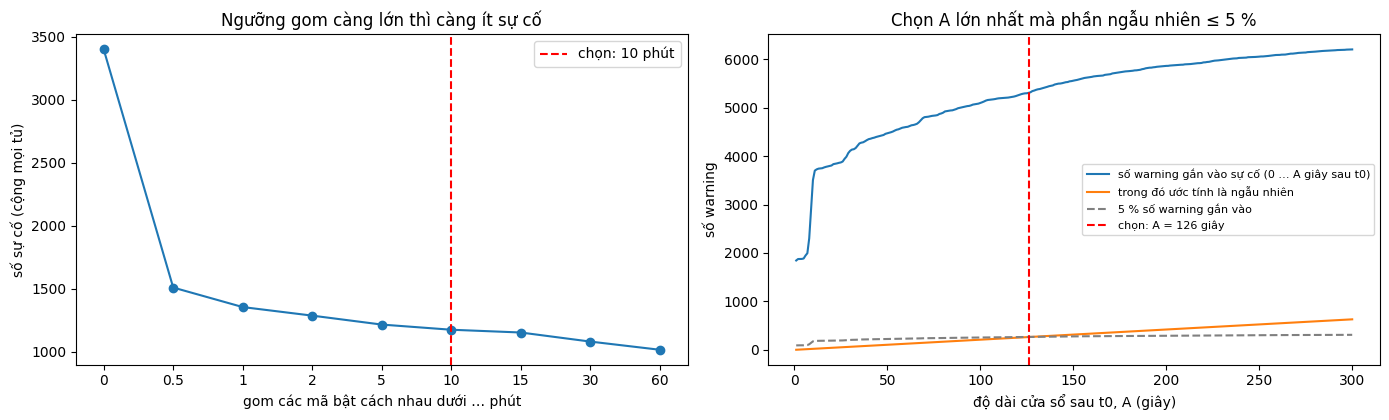

Ngưỡng gom:


,gom_neu_cach_duoi_phut,so_su_co,bot_them_khi_tang_len_muc_sau
0,0.0,3400,55.6%
1,0.5,1509,10.3%
2,1.0,1354,5.0%
3,2.0,1286,5.5%
4,5.0,1215,3.4%
5,10.0,1174,1.9%
6,15.0,1152,6.2%
7,30.0,1080,6.0%
8,60.0,1015,


,giay,gan_sau,ngau_nhien,ty_le_ngau_nhien
9,10,3505,21.0,1%
29,30,4109,63.0,2%
59,60,4600,126.0,3%
89,90,5005,189.0,4%
119,120,5252,252.0,5%
149,150,5557,315.0,6%
199,200,5862,420.0,7%
299,300,6202,630.0,10%


KẾT QUẢ (100 tủ):  gom 10 phút;  warning −1 … +126 giây
Đang dùng (16 tủ): gom 2 phút;  warning −2 … +142 giây
Đã lưu: /content/drive/MyDrive/SINACON_mo_hinh_lai/bang_trung_gian/thang_4_6/cua_so.json


In [6]:
#@title 4. Tính cửa sổ thời gian từ các file nhỏ (vài giây)
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sinacon import calibrate as cal, incidents as inc, explore as ex

R = cal.RULE
eps_list, offs, tus = [], [], []
for f in sorted(OUT.glob('*.pkl.gz')):
    x = pd.read_pickle(f)
    eps_list.append(inc.code_episodes(x['errors']))
    offs.append(ex.warning_offsets(x['errors'], x['warnings'])['giay'].to_numpy(float))
    tus.append(f.name[:-len('.pkl.gz')])
d = np.concatenate(offs)
print(f'Dữ liệu: {OUT.name}, {len(tus)} tủ, {len(d)} lần warning bật')

# (1) ngưỡng gom: thử nhiều ngưỡng, chọn ngưỡng nhỏ nhất mà tăng tiếp chỉ bớt < 2 % số sự cố
N = cal.incident_counts(eps_list, R['gap_candidates_min'])
G = cal.choose_gap(N, R['gap_tol'])
bang_gom = pd.DataFrame({'gom_neu_cach_duoi_phut': N.index, 'so_su_co': N.values})
bang_gom['bot_them_khi_tang_len_muc_sau'] = ((N - N.shift(-1)) / N + 0.0).map(lambda v: '' if pd.isna(v) else f'{v:.1%}').values

# (2) cửa sổ warning: rộng nhất mà phần warning ngẫu nhiên <= 5 %
B, A, nen = cal.choose_warning_window(d, R['max_random_share'], R['far_s'], R['max_s'])
c = cal.window_curve(d, R['far_s'], R['max_s'])
bang_ws = c[c['giay'].isin([10, 30, 60, 90, 120, 150, 200, 300])].copy()
bang_ws['ty_le_ngau_nhien'] = (bang_ws['ngau_nhien'] / bang_ws['gan_sau'].clip(lower=1)).map('{:.0%}'.format)
bang_ws['ngau_nhien'] = bang_ws['ngau_nhien'].round(0)
bang_ws = bang_ws[['giay', 'gan_sau', 'ngau_nhien', 'ty_le_ngau_nhien']]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
ax[0].plot(range(len(N)), N.values, 'o-')
ax[0].set_xticks(range(len(N)), [f'{g:g}' for g in N.index])
ax[0].axvline(list(N.index).index(G), color='red', ls='--', label=f'chọn: {G:g} phút')
ax[0].set_xlabel('gom các mã bật cách nhau dưới … phút'); ax[0].set_ylabel('số sự cố (cộng mọi tủ)')
ax[0].set_title('Ngưỡng gom càng lớn thì càng ít sự cố'); ax[0].legend()
ax[1].plot(c['giay'], c['gan_sau'], label='số warning gắn vào sự cố (0 … A giây sau t0)')
ax[1].plot(c['giay'], c['ngau_nhien'], label='trong đó ước tính là ngẫu nhiên')
ax[1].plot(c['giay'], R['max_random_share'] * c['gan_sau'], '--', color='gray', label='5 % số warning gắn vào')
ax[1].axvline(A, color='red', ls='--', label=f'chọn: A = {A:g} giây')
ax[1].set_xlabel('độ dài cửa sổ sau t0, A (giây)'); ax[1].set_ylabel('số warning')
ax[1].set_title('Chọn A lớn nhất mà phần ngẫu nhiên ≤ 5 %'); ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

print('Ngưỡng gom:'); display(bang_gom)
print(f'Warning: mức nền (đo ở {R["far_s"][0]}–{R["far_s"][1]} giây xa sự cố) = {nen:.3f} lần/giây'); display(bang_ws)
dang = cal.load_windows()
print(f'KẾT QUẢ ({len(tus)} tủ):  gom {G:g} phút;  warning −{B:g} … +{A:g} giây')
print(f'Đang dùng ({len(dang.get("data", {}).get("cabinets", []))} tủ): gom {dang["incident_gap_min"]:g} phút;  '
      f'warning −{dang["warn_before_s"]:g} … +{dang["warn_after_s"]:g} giây')
res = cal.result_from(N, d, R, tus, OUT.name)
(OUT / 'cua_so.json').write_text(json.dumps(res, ensure_ascii=False, indent=1, default=str), encoding='utf-8')
print('Đã lưu:', OUT / 'cua_so.json')
